## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

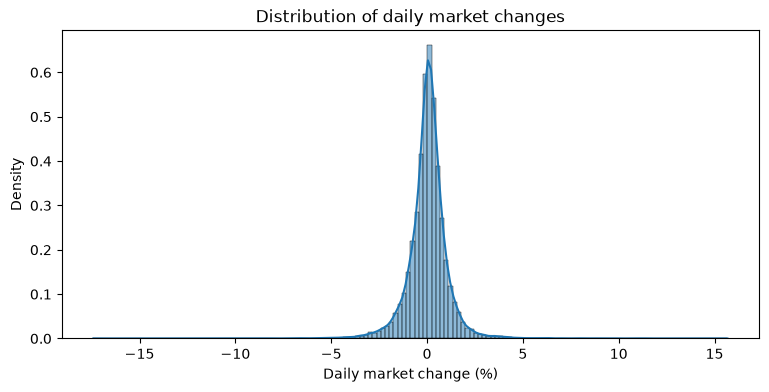

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

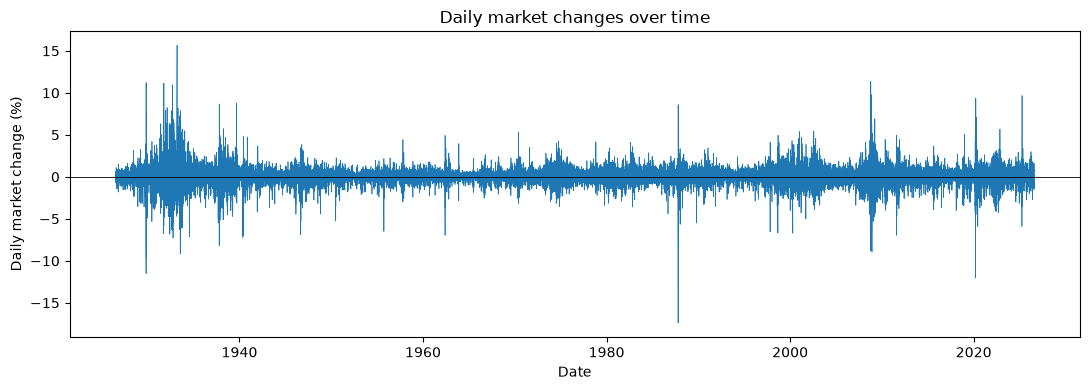

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [ ]:

df['return_t'] = df['market_return_pct']
df['return_tp1'] = df['market_return_pct'].shift(-1)


def two_state(x):
    return np.where(x > 0, 'Up', 'Down')

df['state_t'] = two_state(df['return_t'])
df['state_tp1'] = two_state(df['return_tp1'])

pairs = df.dropna(subset=['return_tp1'])

joint = pd.crosstab(pairs['state_t'], pairs['state_tp1'], normalize=True, margins=True)
print('Joint PMF (rows = today, columns = tomorrow), with marginals:')
print(joint.round(4), '\n')

conditional = pd.crosstab(pairs['state_t'], pairs['state_tp1'], normalize='index')
print('Conditional PMF P(tomorrow | today):')
print(conditional.round(4))

Joint PMF (rows = today, columns = tomorrow), with marginals:
state_tp1    Down      Up     All
state_t                          
Down       0.2247  0.2281  0.4529
Up         0.2281  0.3190  0.5471
All        0.4529  0.5471  1.0000 

Conditional PMF P(tomorrow | today):
state_tp1    Down      Up
state_t                  
Down       0.4962  0.5038
Up         0.4170  0.5830


Transitions into up are more common than down. 54% vs 45%.

It is more likely to transition to an up day from an up day rather than a down day. This is 58% vs 50%.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [ ]:
# Five bins
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['bin_t'] = pd.cut(df['market_return_pct'], bins=bins, labels=labels)
df['bin_tp1'] = df['bin_t'].shift(-1)

print('Days per bin:')
print(df['bin_t'].value_counts().reindex(labels), '\n')

pairs5 = df.dropna(subset=['bin_tp1'])

joint5 = pd.crosstab(pairs5['bin_t'], pairs5['bin_tp1'], normalize=True, margins=True)
print('Joint PMF (rows = today, columns = tomorrow), with marginals:')
print(joint5.round(4), '\n')

top = (pd.crosstab(pairs5['bin_t'], pairs5['bin_tp1'], normalize=True)
       .stack().sort_values(ascending=False))
print('Most likely transitions:')
print(top.head(5).round(4), '\n')

cond5 = pd.crosstab(pairs5['bin_t'], pairs5['bin_tp1'], normalize='index')
print('Conditional PMF P(tomorrow | today):')
print(cond5.round(4), '\n')

print('Two most likely next states:')
for state, row in cond5.iterrows():
    best = row.nlargest(2)
    print(f'  {state:<11} -> {best.index[0]} ({best.iloc[0]:.3f}), {best.index[1]} ({best.iloc[1]:.3f})')
print()

print('Max |P - 0.2| per row:')
print((cond5 - 0.2).abs().max(axis=1).round(3), '\n')

print("Tomorrow's market_return_pct given today's state:")
print(pairs5.groupby('bin_t', observed=True)['return_tp1'].describe().round(3))

Days per bin:
bin_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64 

Joint PMF (rows = today, columns = tomorrow), with marginals:
bin_tp1     Large loss  Small loss  Near zero  Small gain  Large gain     All
bin_t                                                                        
Large loss      0.0213      0.0272     0.0091      0.0278      0.0195  0.1049
Small loss      0.0354      0.0886     0.0342      0.0978      0.0274  0.2834
Near zero       0.0093      0.0420     0.0210      0.0493      0.0093  0.1309
Small gain      0.0250      0.1001     0.0550      0.1594      0.0326  0.3721
Large gain      0.0138      0.0255     0.0116      0.0378      0.0199  0.1087
All             0.1049      0.2834     0.1308      0.3721      0.1087  1.0000 

Most likely transitions:
bin_t       bin_tp1   
Small gain  Small gain    0.1594
            Small loss    0.1001
Small loss  Small gain    0.0978
            Small loss

The most common bin was small gains, and then it was small loss. The next was near zero. Large loss is least common.

The most likely transitions are small gain -> small gain (15.9%), small gain -> small loss (10%), small loss -> small gain (9.8%), and small loss -> small loss (8.9%).

For each current state, the most liekly next state are small gain and small loss. large loss is the closest to the uniform .2 per state with the farthest difference around .11 from .2. small gain is farthest from uniform at .2 because .43 is the stat for followed by another small gain. The next state is fairly hard to predict becasue the rows are spread out and the best guess is always small gain.

Looking at tomorrow's market return pct based on the current state we see that after a large loss the meand is -.038%, after a small loss it is -.04%, near zero is .015%, small gain is   .17%, and large gaim is .1633%. The min and max for each state show the most extreme days follow large moves, there is a bigger minimum and maximum for large losses and large gains, while the small losses or gains have lower min and max next days. This shows that the pattern for volatility is that there are clusters of large swings. The highest standard deviations appear after large losses or gains.



### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

Return range of each bin (%):
y_t     0     1     2     3     4     5     6     7     8     9   ...    11  \
min -17.41 -1.61 -1.06 -0.78 -0.56 -0.41 -0.29 -0.18 -0.11 -0.03  ...  0.11   
max  -1.61 -1.07 -0.78 -0.57 -0.42 -0.30 -0.19 -0.11 -0.03  0.04  ...  0.18   

y_t    12    13    14    15    16    17    18    19     20  
min  0.19  0.27  0.35  0.45  0.55  0.68  0.84  1.10   1.56  
max  0.26  0.34  0.44  0.54  0.67  0.84  1.09  1.55  15.67  

[2 rows x 21 columns] 



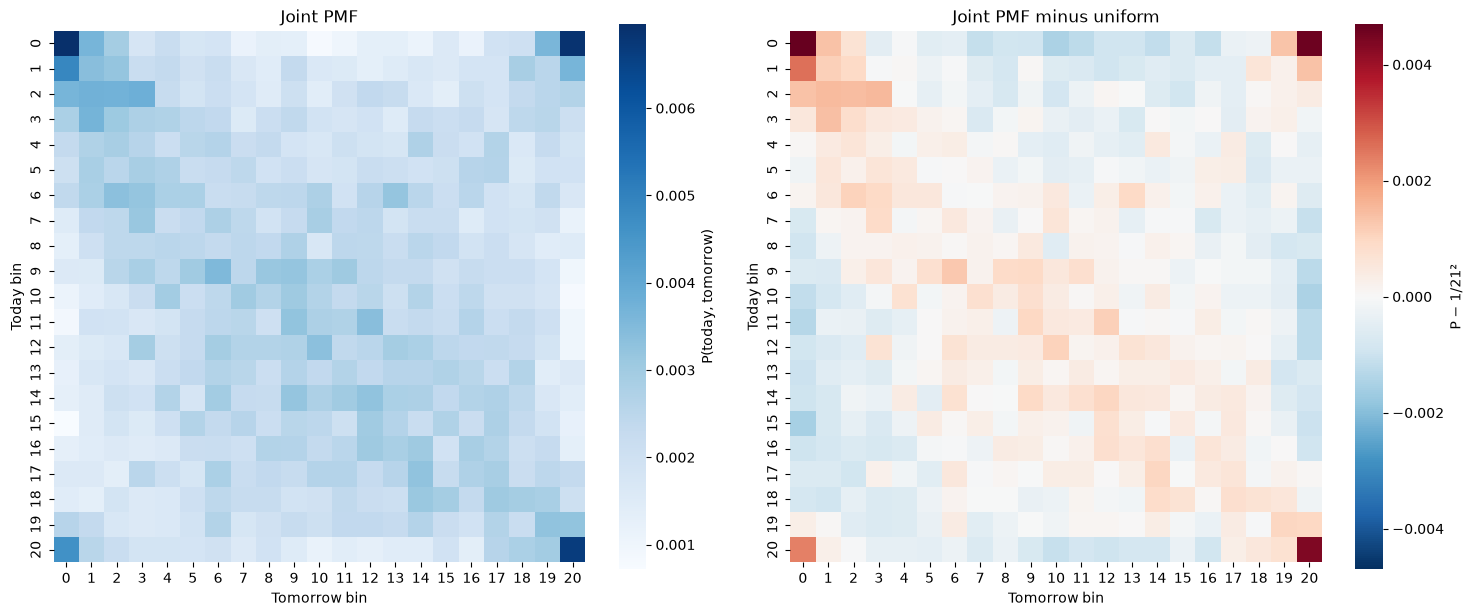

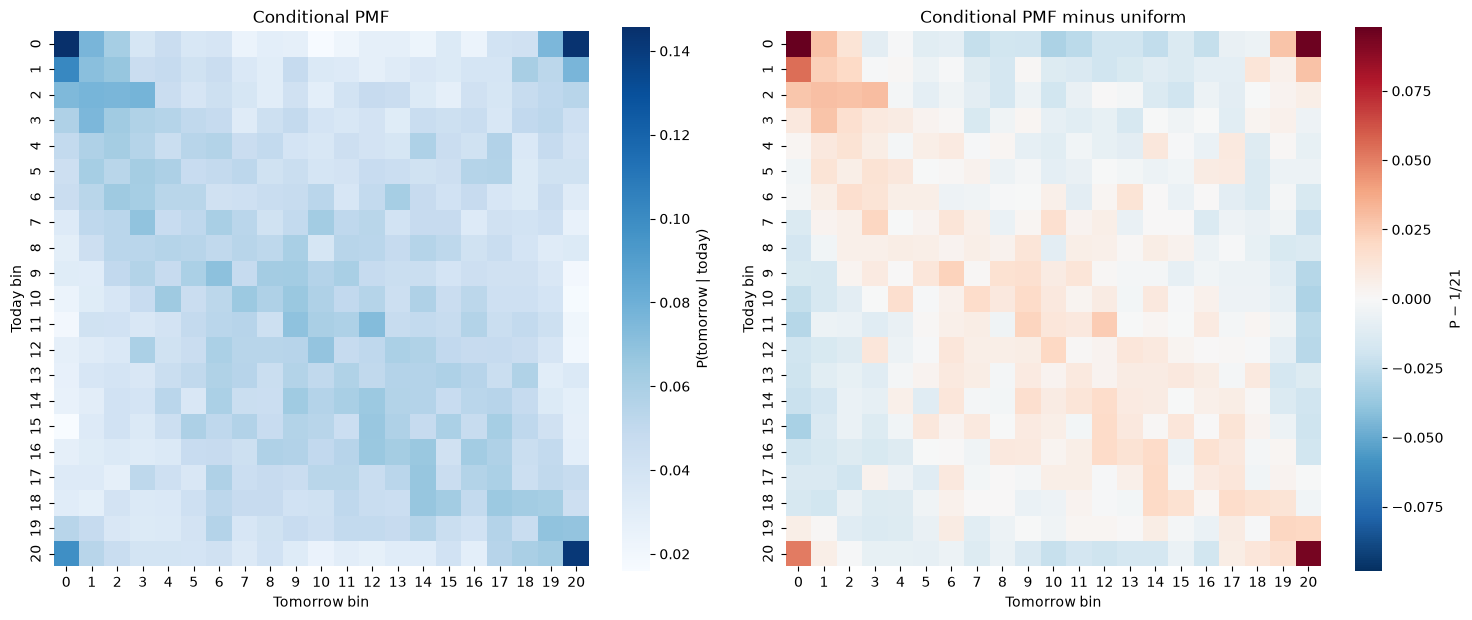

Tomorrow's market_return_pct by today's bin:
       min   mean    max    std
y_t                            
0   -17.41 -0.014  11.22  2.140
1    -7.36 -0.077   6.36  1.286
2    -8.79 -0.097  11.36  1.228
3    -8.28 -0.059   6.16  1.050
4    -6.89 -0.024   4.56  0.989
5   -11.23 -0.023   6.37  1.025
6    -3.94 -0.030   7.37  0.930
7    -3.40 -0.014   4.76  0.836
8    -6.00  0.026   5.49  0.853
9    -8.19 -0.013   3.60  0.812
10   -7.30  0.035   4.69  0.805
11   -8.25  0.092   7.88  0.792
12   -6.82  0.057   5.66  0.784
13   -5.12  0.088   4.16  0.817
14   -6.49  0.091   5.70  0.831
15   -6.99  0.126   8.67  0.790
16   -7.13  0.126   4.84  0.827
17   -6.30  0.130   8.60  0.960
18   -8.96  0.175   4.38  0.901
19   -4.93  0.133   6.04  1.100
20  -12.00  0.195  15.67  1.703


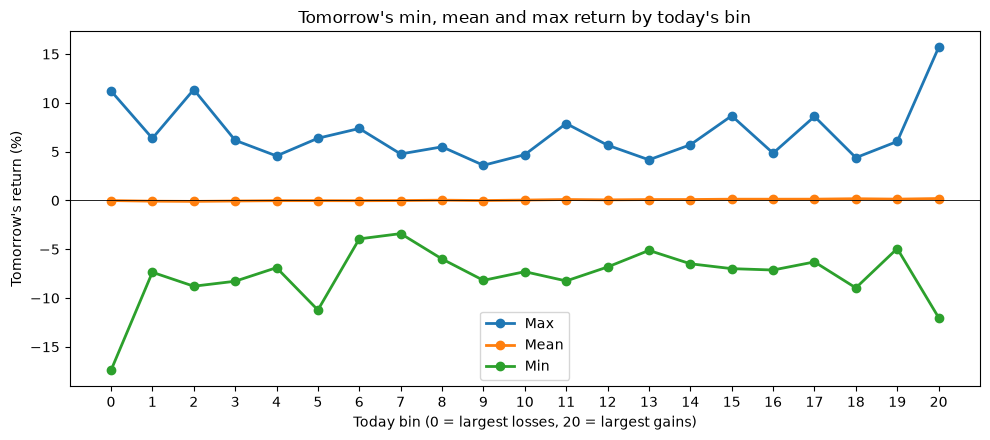

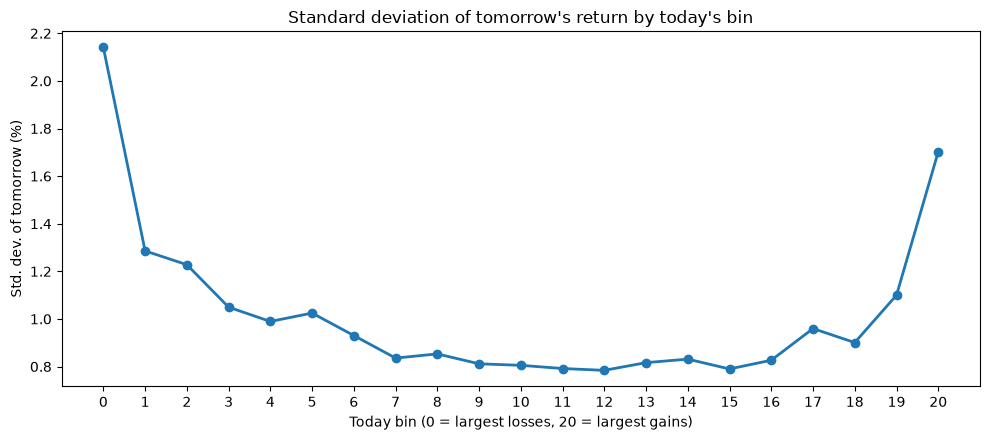

In [ ]:
n_bins = 21

# 21 equal bins
df['y_t'] = pd.qcut(df['market_return_pct'], q=n_bins, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['return_tp1'] = df['market_return_pct'].shift(-1)

pairs21 = df.dropna(subset=['y_tp1']).astype({'y_tp1': int})

print('Return range of each bin (%):')
print(df.groupby('y_t')['market_return_pct'].agg(['min', 'max']).round(2).T, '\n')


joint21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(joint21, cmap='Blues', square=True, ax=axes[0],
            cbar_kws={'label': 'P(today, tomorrow)'})
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')

dev = joint21 - 1 / n_bins**2
lim = dev.abs().max().max()
sns.heatmap(dev, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, square=True, ax=axes[1],
            cbar_kws={'label': 'P − 1/21²'})
axes[1].set(title='Joint PMF minus uniform', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

cond21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cond21, cmap='Blues', square=True, ax=axes[0],
            cbar_kws={'label': 'P(tomorrow | today)'})
axes[0].set(title='Conditional PMF', xlabel='Tomorrow bin', ylabel='Today bin')

dev = cond21 - 1 / n_bins
lim = dev.abs().max().max()
sns.heatmap(dev, cmap='RdBu_r', center=0, vmin=-lim, vmax=lim, square=True, ax=axes[1],
            cbar_kws={'label': 'P − 1/21'})
axes[1].set(title='Conditional PMF minus uniform', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

next_stats = pairs21.groupby('y_t')['return_tp1'].agg(['min', 'mean', 'max', 'std'])
print("Tomorrow's market_return_pct by today's bin:")
print(next_stats.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(next_stats.index, next_stats['max'], marker='o', linewidth=2, label='Max')
ax.plot(next_stats.index, next_stats['mean'], marker='o', linewidth=2, label='Mean')
ax.plot(next_stats.index, next_stats['min'], marker='o', linewidth=2, label='Min')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Today bin (0 = largest losses, 20 = largest gains)',
       ylabel="Tomorrow's return (%)", title="Tomorrow's min, mean and max return by today's bin",
       xticks=range(n_bins))
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(next_stats.index, next_stats['std'], marker='o', linewidth=2)
ax.set(xlabel='Today bin (0 = largest losses, 20 = largest gains)',
       ylabel='Std. dev. of tomorrow (%)', title="Standard deviation of tomorrow's return by today's bin",
       xticks=range(n_bins))
fig.tight_layout()
plt.show()

Some clear patterns appear in the joint and conditional PMF heatmaps. The far corners have the highest probability, which shows that when a day is in the extreme bin, it is most likely going to be in an extreme bin again in either direction. The pattern does not help predict which direction the next day will be in, just that it will likely also be large. FOr both PMFs, after subtracting the uniform distribution, the x patterns became more intense.

The mean for all the next days after the current day is barely different from 0. The min and maxes mirror each other, getting wider apart at the extreme ends. Besides the ends, the bins in the center do not change much from each other. The graph of the standard deviation looks u shaped. The deviations are much higher at the ends, while there is not a major difference in the middle bins. 

This information all shows that the market is really difficult to predict. There is not good information about the direction of the next day's return, but sometimes you may be able to tell the magnitude of the next day, especially if the current day has been extreme in one way. .